# VAE latent spaces on the Nature data: the standard VAE and the β grid

The awareness plan (Live_Update, section 3.3) runs a **standard VAE** (β = 1, raw 1 s input, three seeds) and a
**β grid**: β in {1, 8, 32, 64, 128} × decoder variance {fixed, learned} × seeds 0–2, 30 runs in one SLURM array, on 1 s
raw input; and, on 3 s + spectral input, the cells the 1 s scoring made worth testing (β 1, 32, 64, 128 fixed, β 1
learned; 15 runs, `submit.sh --vae --inputs raw_3s_spectral`). The input ablation adds 1 s + spectral and 3 s without
spectral (β 1, 32, 128 fixed, β 1 learned; `submit.sh --vae --inputs raw_1s_spectral` or `raw_3s`). The LSTM-VAE and the
Transformer VAE have their own notebooks (03, 04), built from this one. This
notebook reads the pulled runs and shows what their latent spaces look like. It scores nothing: LOF, reconstruction
error and the other detection scores belong to notebook 05, which picks up the same run folders (labelled by stem,
e.g. `vae_b8_learned`) once they are pulled. Selection is on the validation participants and the test participants are
scored once, at the end, so every view here uses the **four validation participants** (BT09, BT12, BT13, BT21).

**Model and training** (`ml/nature/awareness/train_vae.py`; model `ml/common/models/vae.py`): the Nature AE's trunk and
decoder with Gaussian mean and log-variance heads, 4 × 8 = 32 latent dimensions, trained like the AE (same arrays,
participants, Adam at lr 0.003, batch 1,024, early stopping with patience 5 on the validation negative ELBO). **Fixed**
decoder variance is the unit-variance likelihood of the Science Robotics study; **learned** adds one decoder variance per
input channel (a calibrated decoder), the change that could make the posterior carry something the AE's latent does
not (Live_Update 3.1).

**Running it** (laptop commands need the cluster session open; login-node commands run in `~/Uncertainty-Aware-Hip-Exoskeleton`):

| where | command | what |
|---|---|---|
| laptop | `bash ml/nature/awareness/slurm/push.sh` | code and arrays to the cluster |
| login node | `bash ml/nature/awareness/slurm/submit.sh --vae --smoke` | two-epoch wiring check of cell 0 on gpu_test |
| login node | `bash ml/nature/awareness/slurm/submit.sh --vae --array 0` | the standard VAE, seed 0; then `jobstats <jobid>` (CLAUDE.md rule 4) |
| login node | `bash ml/nature/awareness/slurm/submit.sh --vae --array 1-29` | the rest of the grid (`python ml/nature/awareness/train_vae.py --list`) |
| laptop | `bash ml/nature/awareness/slurm/pull.sh` | runs to `notebooks/nature/model_exploration/runs/vae/`, then rerun this notebook |

A finished cell is skipped on resubmission (`--force` retrains it), so a partly failed array can be resubmitted whole.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _latent_views as lv
import _vae_runs as vr
import _novelty_scores as ns

ARCH, MODEL_PREFIX, TAG, NB = 'conv', 'VAE ·', 'vae', '02'   # architecture shown here and figure prefix (02 conv, 03 LSTM, 04 Transformer)
RUNS = Path(os.environ.get('HIPEXO_VAE_RUNS', REPO / 'notebooks' / 'nature' / 'model_exploration' / 'runs' / 'vae'))
DATA = REPO / 'data' / 'processed_nature' / 'ae'                              # built by ml/nature/awareness/ae_data.py
VIEW_CACHE = REPO / 'data' / 'cache' / 'nature' / 'vae_views'
SHOWN_SEED = 0
FIG_DIR = Path.cwd() / 'figures'                                            # figures for Live_Update
FIG_DIR.mkdir(exist_ok = True)
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
found = vr.discover_vae_runs(RUNS, ARCH)
HAVE_RUNS = not found.empty
if HAVE_RUNS:
    runs = {r.run: vr.load_vae_run(r.run, tables[r.inputs]) for r in found.itertuples()}
    print(f'{len(found)} runs in {found.groupby(vr.CELL_COLS).ngroups} cells under {RUNS}; '
          f'code {sorted({r["summary"]["git_sha"] for r in runs.values()})}')
    display(found.pivot_table(index = ['inputs', 'decoder_variance'], columns = 'beta', values = 'seed', aggfunc = 'count').fillna(0).astype(int))
else:
    print(f'No finished {ARCH} VAE runs under {RUNS} yet. Run the grid on the cluster and pull it (commands above), then rerun.')

69 runs in 23 cells under /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/nature/model_exploration/runs/vae; code ['248e43c-dirty']


beta                              1.0    8.0    32.0   64.0   128.0
inputs          decoder_variance                                   
raw_1s          fixed                 3      3      3      3      3
                learned               3      3      3      3      3
raw_1s_spectral fixed                 3      0      3      0      3
                learned               3      0      0      0      0
raw_3s          fixed                 3      0      3      0      3
                learned               3      0      0      0      0
raw_3s_spectral fixed                 3      0      3      3      3
                learned               3      0      0      0      0

## 1. What was trained

Validation participants, familiar windows for training and early stopping; NLL and KL are per window (summed over its
channels and samples, 16 × 200 on 1 s raw input, 23 channels with the spectral features and 600 samples at 3 s, and
over the 32 latent dimensions). A dimension is *active* when its median posterior
variance on the familiar validation windows is below 0.9 (the Science Robotics study's definition).

In [2]:
if HAVE_RUNS:
    cells, per_seed = vr.get_cell_table(runs, found)
    display(cells)
    display(per_seed.round(4))

seeds best epoch val NLL / window val KL / window          val MSE active dims (of 32)    minutes
inputs          decoder_variance beta                                                                                                    
raw_1s          fixed            1.0        3     41 ± 4     3334.1 ± 4.7    60.20 ± 0.27  0.2459 ± 0.0030          32.0 ± 0.0  3.4 ± 0.5
                                 8.0        3     33 ± 9     3439.5 ± 9.0    17.35 ± 0.10  0.3118 ± 0.0056          18.7 ± 1.5  2.7 ± 0.4
                                 32.0       3     12 ± 7     3586.8 ± 4.7     6.51 ± 0.09  0.4039 ± 0.0029           8.0 ± 0.0  1.4 ± 0.3
                                 64.0       3    18 ± 10    3656.9 ± 11.4     3.91 ± 0.13  0.4477 ± 0.0071           8.0 ± 0.0  1.9 ± 0.7
                                 128.0      3      4 ± 1     3788.4 ± 6.7     1.94 ± 0.08  0.5299 ± 0.0042           8.0 ± 0.0  0.8 ± 0.1
                learned          1.0        3     48 ± 4    1474.8 ± 36.1   107.76 ± 2.39  0.2765 ± 0.0065          32.0 ± 0.0  3.6 ± 0.2
                                 8.0        3    40 ± 26    1579.9 ± 67.7    57.19 ± 2.19  0.2877 ± 0.0027          32.0 ± 0.0  3.2 ± 1.5
                                 32.0       3     27 ± 5    2417.3 ± 84.1    15.42 ± 1.01  0.3675 ± 0.0095          16.0 ± 0.0  2.3 ± 0.3
                                 64.0       3     24 ± 2     2653.5 ± 5.4     9.38 ± 0.03  0.3874 ± 0.0017           8.0 ± 0.0  2.1 ± 0.2
                                 128.0      3     15 ± 4    2960.4 ± 20.4     4.99 ± 0.11  0.4326 ± 0.0020           8.0 ± 0.0  1.5 ± 0.2
raw_1s_spectral fixed            1.0        3     47 ± 6     4709.7 ± 7.7    64.69 ± 0.74  0.2098 ± 0.0033          32.0 ± 0.0  3.3 ± 0.3
                                 32.0       3     15 ± 5     4973.8 ± 9.8     8.10 ± 0.31  0.3246 ± 0.0043           8.0 ± 0.0  1.4 ± 0.3
                                 128.0      3      8 ± 1    5172.8 ± 10.8     3.10 ± 0.09  0.4112 ± 0.0047           8.0 ± 0.0  1.1 ± 0.0
                learned          1.0        3    43 ± 10   1285.5 ± 132.7   118.46 ± 4.65  0.2626 ± 0.0115          32.0 ± 0.0  3.1 ± 0.5
raw_3s          fixed            1.0        3     44 ± 6    10368.2 ± 9.8    80.74 ± 1.08  0.3222 ± 0.0020          32.0 ± 0.0  5.3 ± 0.7
                                 32.0       3    22 ± 15   10664.8 ± 22.2    15.10 ± 0.44  0.3840 ± 0.0046          16.0 ± 0.0  3.3 ± 1.4
                                 128.0      3     10 ± 4   11033.7 ± 43.3     6.03 ± 0.07  0.4608 ± 0.0090           8.0 ± 0.0  2.1 ± 0.3
                learned          1.0        3    48 ± 10    6518.1 ± 52.6   119.43 ± 0.91  0.3486 ± 0.0031          32.0 ± 0.0  5.9 ± 1.0
raw_3s_spectral fixed            1.0        3     47 ± 6   14504.5 ± 24.8    84.92 ± 2.16  0.2642 ± 0.0036          32.0 ± 0.0  6.1 ± 0.9
                                 32.0       3     24 ± 2   14877.6 ± 28.8    16.34 ± 0.22  0.3183 ± 0.0042          18.3 ± 4.0  3.3 ± 0.2
                                 64.0       3     20 ± 2   15030.5 ± 17.0    11.18 ± 0.08  0.3405 ± 0.0025          13.3 ± 4.6  3.2 ± 0.2
                                 128.0      3      9 ± 3   15243.7 ± 19.9     7.33 ± 0.09  0.3713 ± 0.0029          13.7 ± 4.0  1.8 ± 0.4
                learned          1.0        3    39 ± 14   4818.7 ± 388.5   137.46 ± 0.74  0.3005 ± 0.0054          32.0 ± 0.0  4.9 ± 1.5

best epoch  val NLL / window  val KL / window  val MSE  active dims (of 32)  minutes
inputs          decoder_variance beta  seed                                                                                      
raw_1s          fixed            1.0   0             38         3328.7542          59.9961   0.2426                   32     2.93
                                       1             45         3335.8457          60.0982   0.2470                   32     3.30
                                       2             40         3337.7363          60.5009   0.2482                   32     3.83
                                 8.0   0             38         3433.7444          17.2669   0.3082                   20     2.95
                                       1             38         3434.7739          17.4606   0.3089                   19     2.84
...                                                 ...               ...              ...      ...                  ...      ...
raw_3s_spectral fixed            128.0 1             12        15221.7041           7.4272   0.3682                   16     2.26
                                       2              7        15248.6299           7.3035   0.3721                    9     1.55
                learned          1.0   0             56         4372.2739         138.2966   0.3063                   32     6.60
                                       1             31         5003.9746         136.8960   0.2957                   32     4.03
                                       2             31         5079.9194         137.1948   0.2994                   32     4.03

[69 rows x 6 columns]

## 2. Training curves

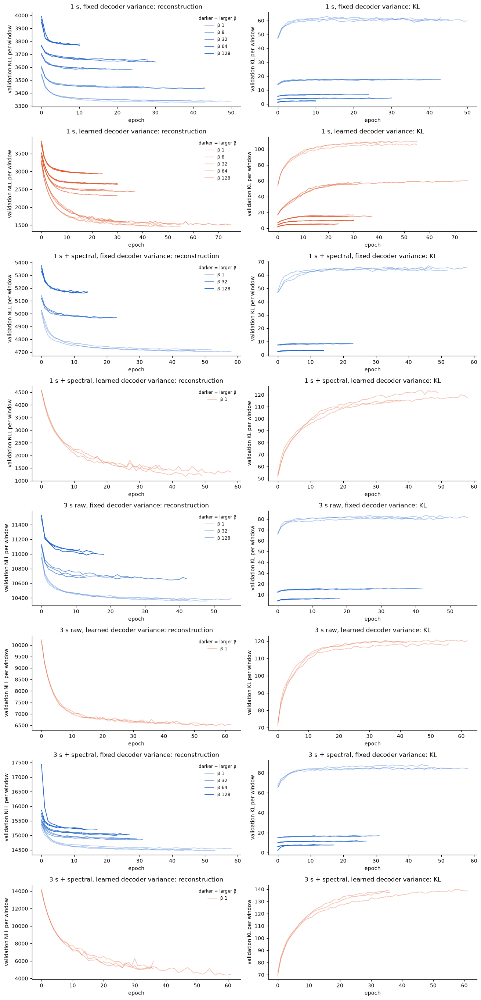

In [3]:
if HAVE_RUNS:
    vr.plot_curves(runs, found)

## 3. How much of the code each VAE uses

Active dimensions and KL against β. With the variance fixed, the Science Robotics sweep went from 32 active dimensions
at β = 1 to 8 at β = 16 and 32; the learned variance changes how much the reconstruction term weighs against the KL, so
the same β need not give the same code.

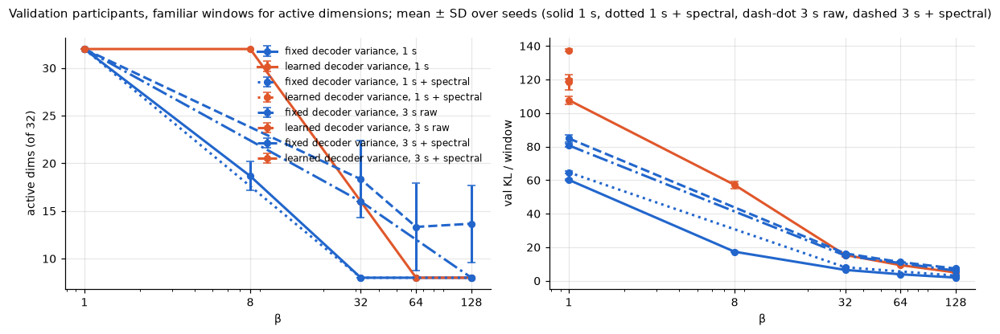

In [4]:
if HAVE_RUNS:
    vr.plot_active_and_kl(per_seed, FIG_DIR / f'{NB}_{TAG}_active_kl.png')

### 3.1 KL per latent dimension

Mean KL of each dimension over the validation participants' windows (seed 0): which of the 32 dimensions carry
information, and whether the same ones survive as β grows. Columns are the 4 filters × 8 time steps.

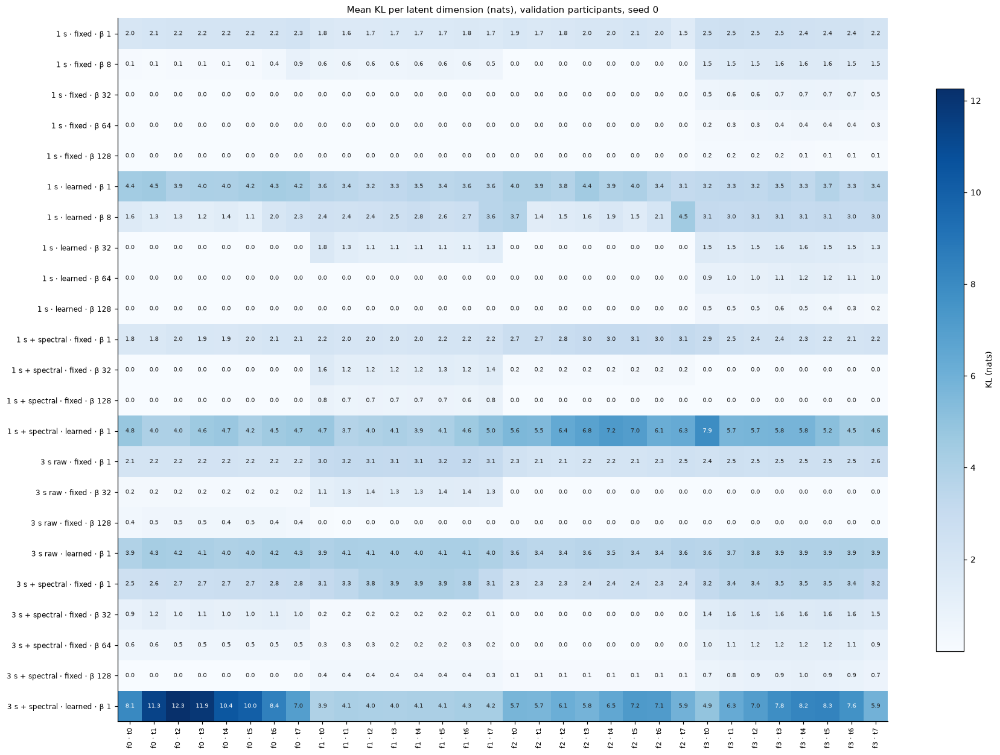

In [5]:
if HAVE_RUNS:
    shown = found[found['seed'] == SHOWN_SEED]
    grid = pd.DataFrame({vr.get_cell_label(r.inputs, r.decoder_variance, r.beta): vr.get_kl_per_dim(runs[r.run]['z'], runs[r.run]['logvar'])
                         for r in shown.itertuples()}).T
    grid.columns = [f'f{u // 8} · t{u % 8}' for u in grid.columns]
    vr.plot_heatmap(grid, f'Mean KL per latent dimension (nats), validation participants, seed {SHOWN_SEED}', 'KL (nats)', '{:.1f}')

## 4. The learned decoder variance

Decoder standard deviation per input channel, in standardized units (1 = the channel's training SD), for the
learned-variance runs: which channels the decoder reconstructs confidently. The fixed-variance runs have 1 everywhere.

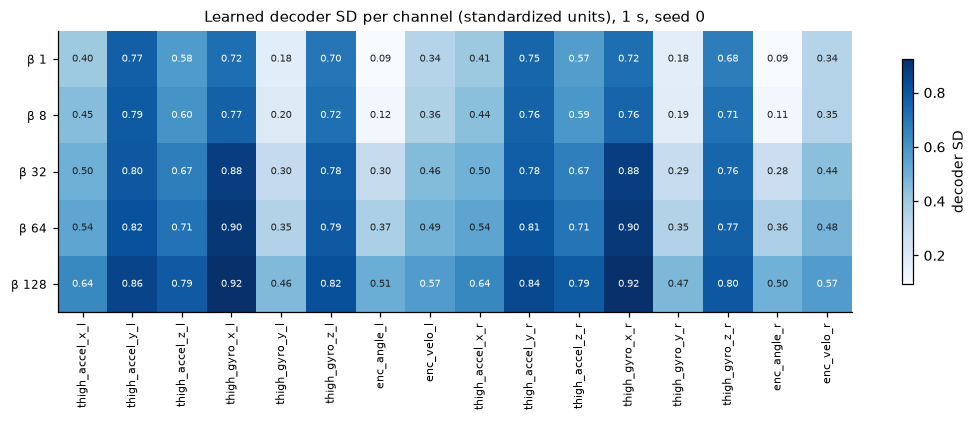

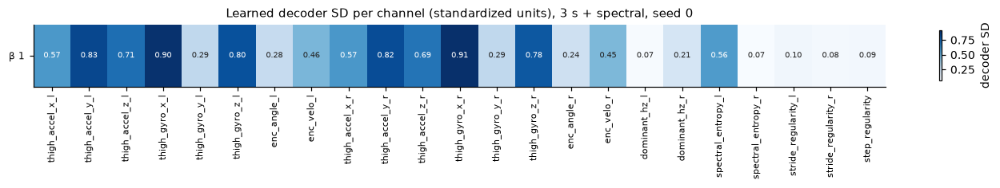

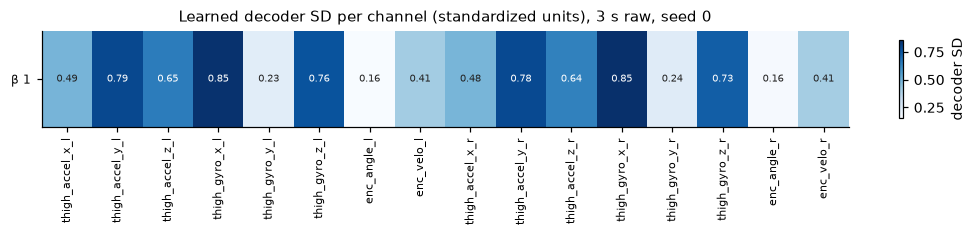

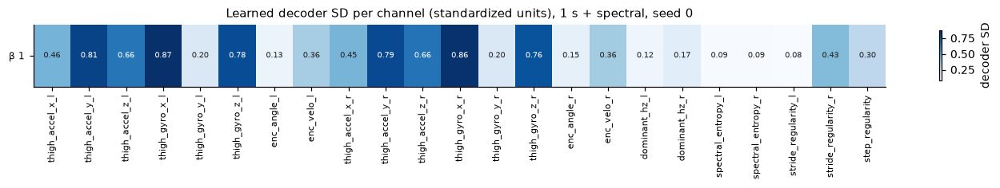

In [6]:
if HAVE_RUNS:
    for inputs, spec in meta['inputs'].items():
        learned = found[(found['decoder_variance'] == 'learned') & (found['seed'] == SHOWN_SEED) & (found['inputs'] == inputs)]
        if learned.empty:
            continue
        channel_names = meta['channels'] + list(spec['features'])
        sigma = pd.DataFrame({f'β {r.beta:g}': runs[r.run]['summary']['decoder_sigma'] for r in learned.itertuples()}, index = channel_names).T
        vr.plot_heatmap(sigma, f'Learned decoder SD per channel (standardized units), {vr.INPUT_SHORT[inputs]}, seed {SHOWN_SEED}', 'decoder SD',
                        '{:.2f}', save = FIG_DIR / f'{NB}_{TAG}_decoder_sigma_{inputs}.png')


## 5. Posterior width by task

Median over each task's validation windows of the mean posterior variance across the run's active dimensions (seed 0).
With the variance fixed, the Science Robotics study found this flat across tasks; this shows whether it still is.
Descriptive only: how well it separates unfamiliar movement is a score, and is notebook 05's.

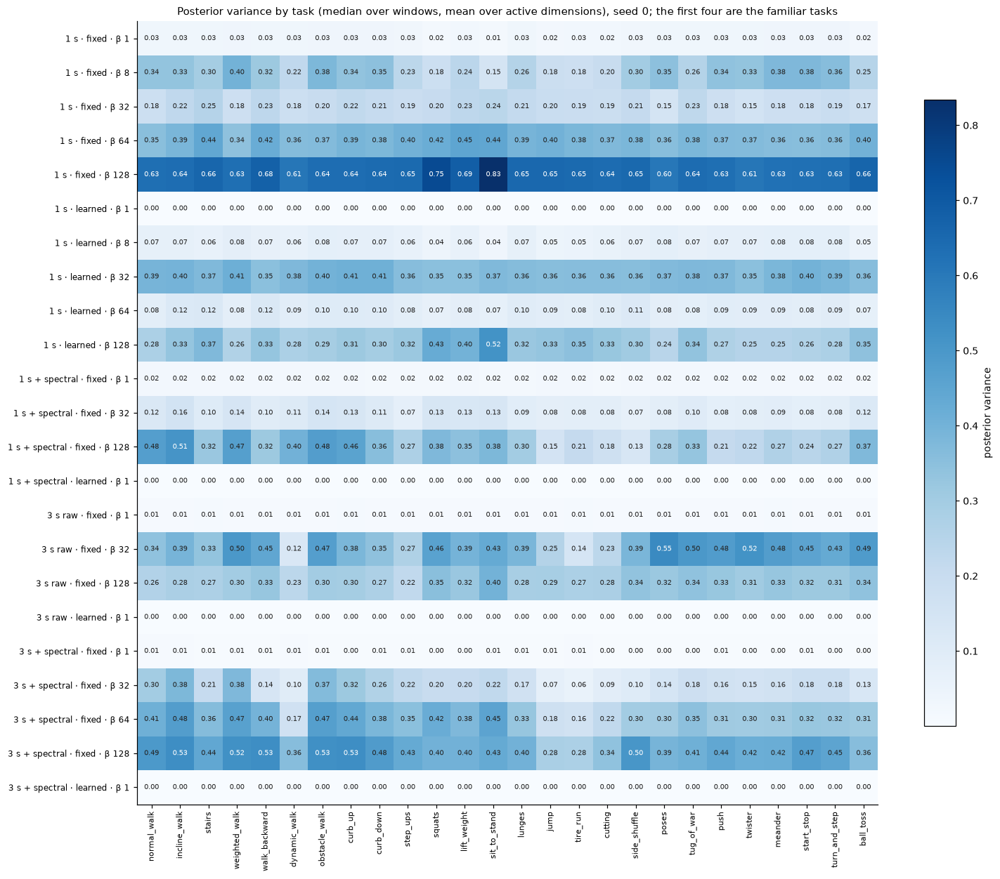

In [7]:
if HAVE_RUNS:
    tasks = list(nt.ID_SAFE_TASKS) + [t for ts in nt.TASK_FAMILIES.values() for t in ts if t not in nt.ID_SAFE_TASKS]
    widths = {}
    for r in shown.itertuples():
        run = runs[r.run]
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        widths[vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)] = vr.get_width_by_task(run['labels'], run['logvar'],
                                                                            vr.get_active(run['logvar'], familiar))
    width = pd.DataFrame(widths).T.reindex(columns = tasks)
    vr.plot_heatmap(width, f'Posterior variance by task (median over windows, mean over active dimensions), seed {SHOWN_SEED}; '
                    'the first four are the familiar tasks', 'posterior variance', '{:.2f}')

## 6. Latent maps

Posterior means of up to 250 validation windows per task (the same windows for every run), on the run's active
dimensions, in the three views of notebook 01 (the highest-variance dimensions, PCA, UMAP), coloured by task family and
by controller class. One row per β for each input and decoder variance, seed 0. The windows are
those every run exported, so 1 s and 3 s models are drawn on the same windows.

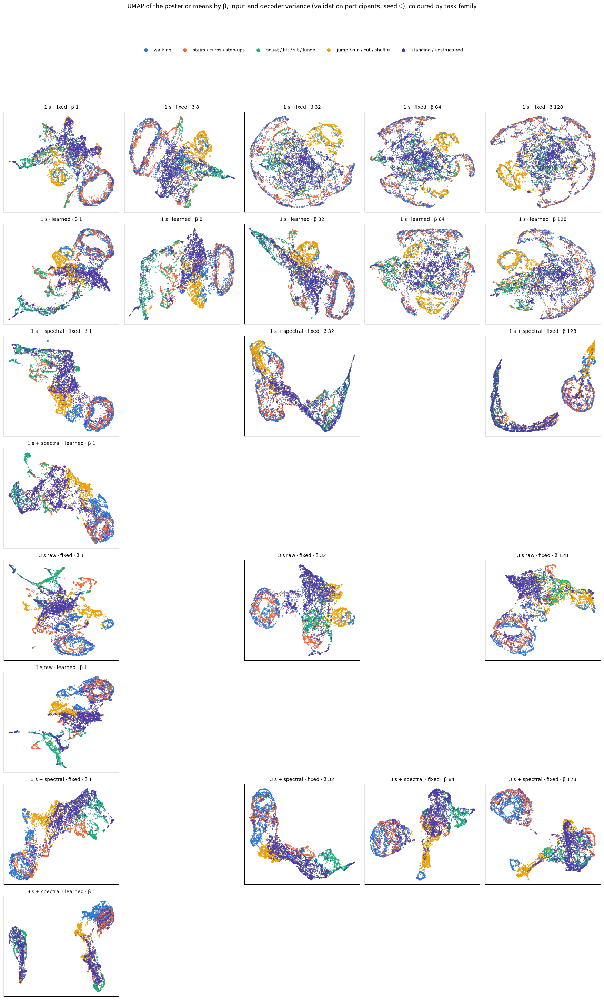

6,500 validation windows, 26 tasks, participants ['BT09', 'BT12', 'BT13', 'BT21']


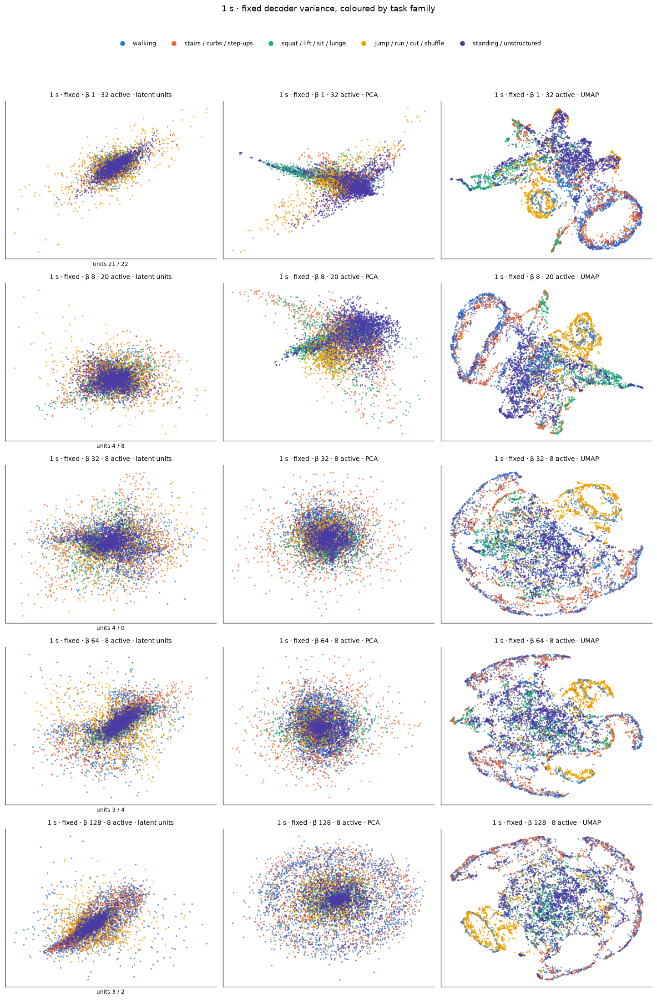

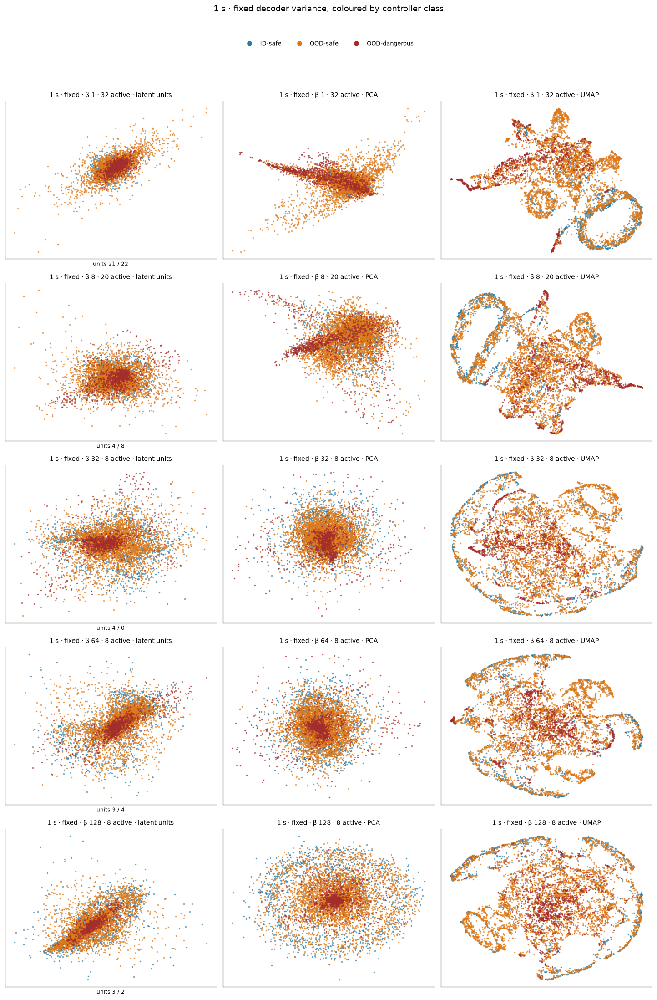

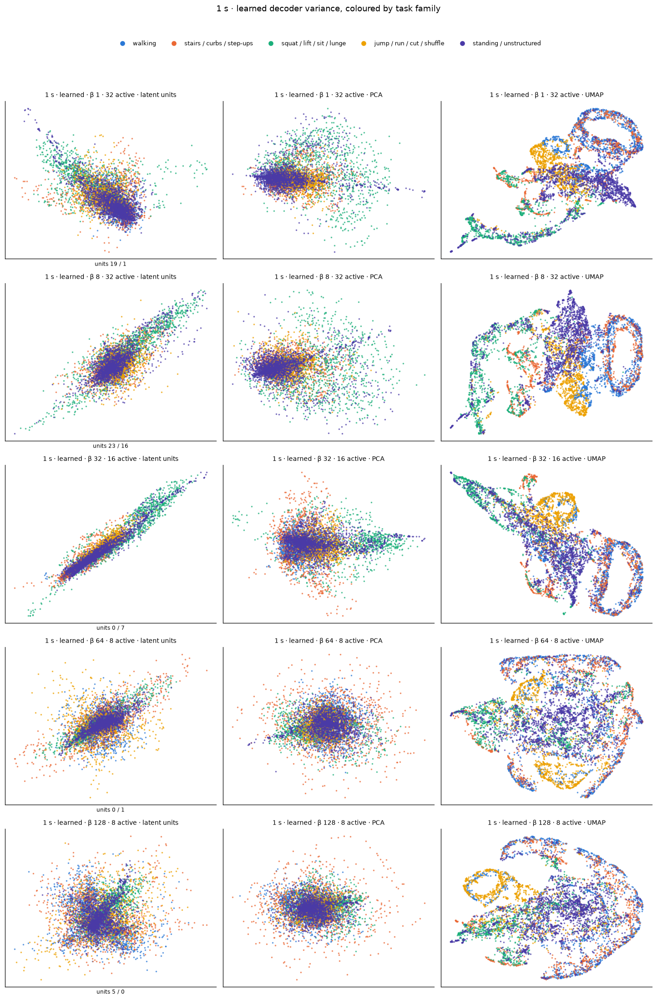

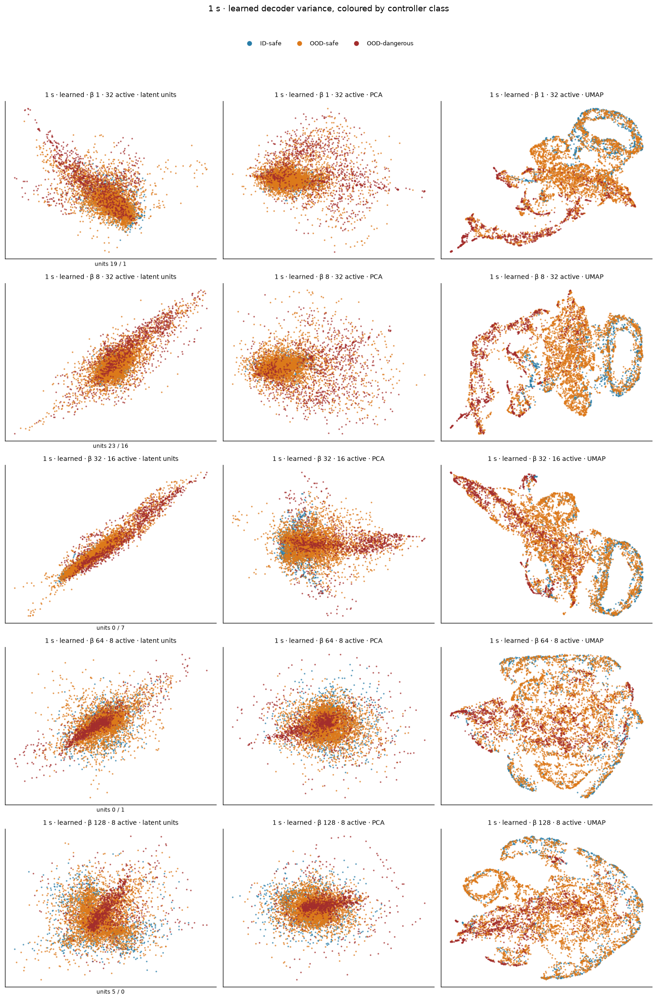

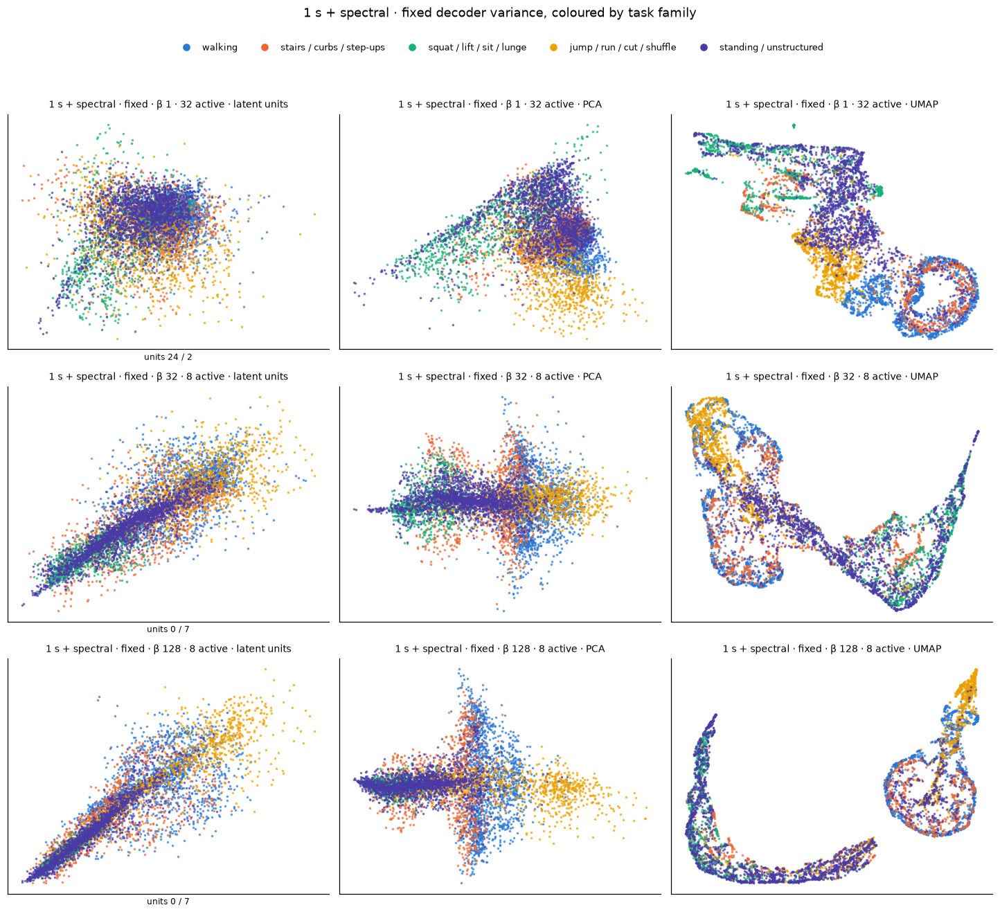

...

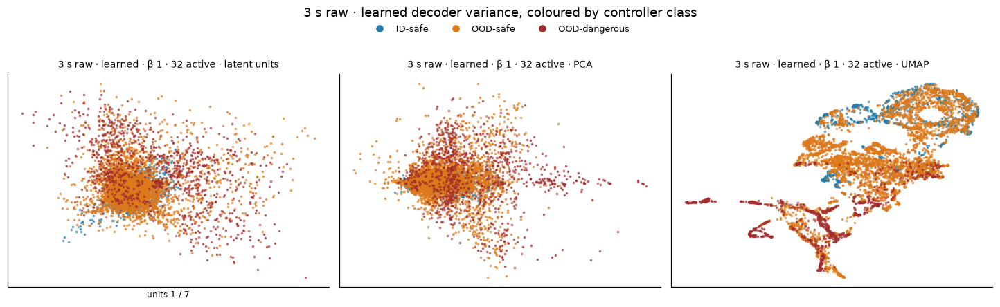

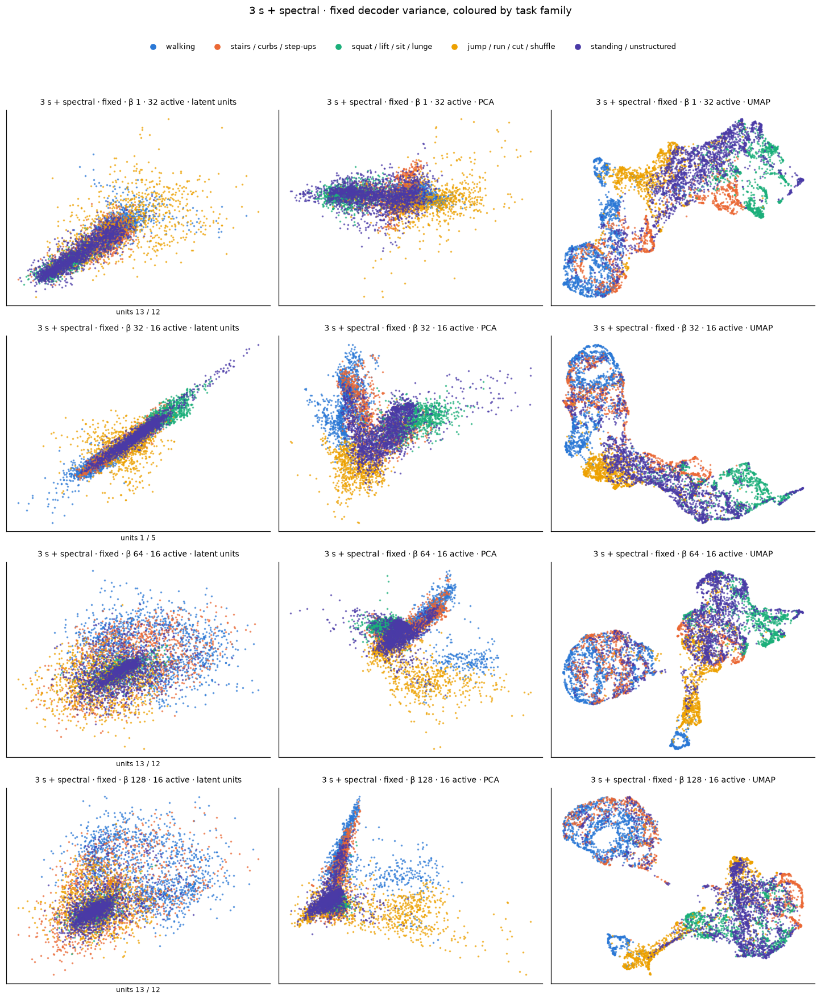

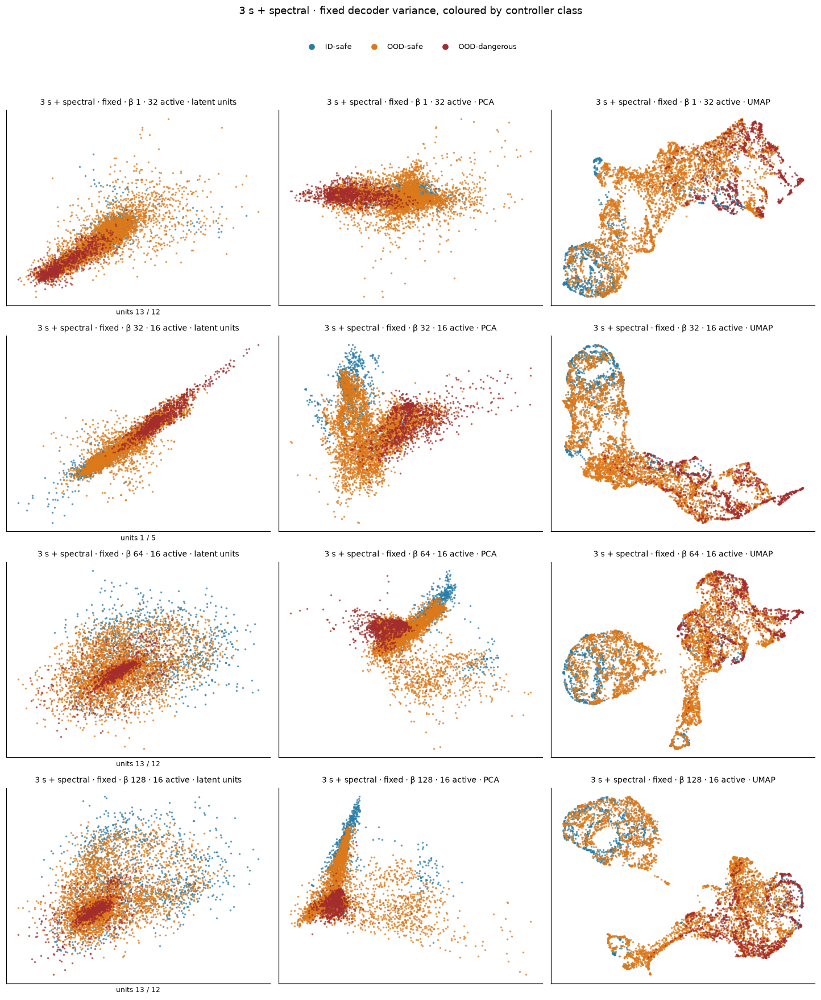

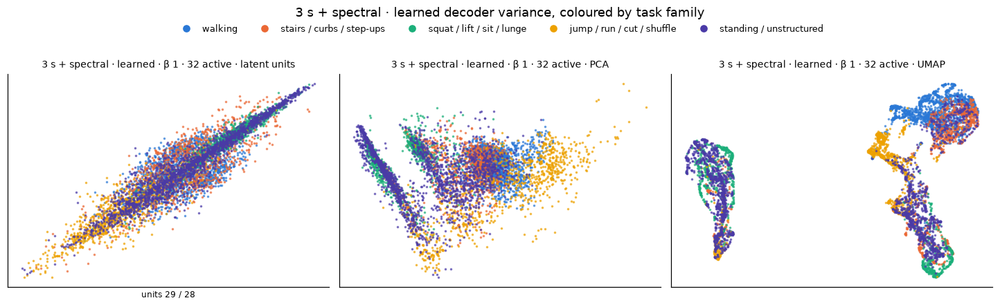

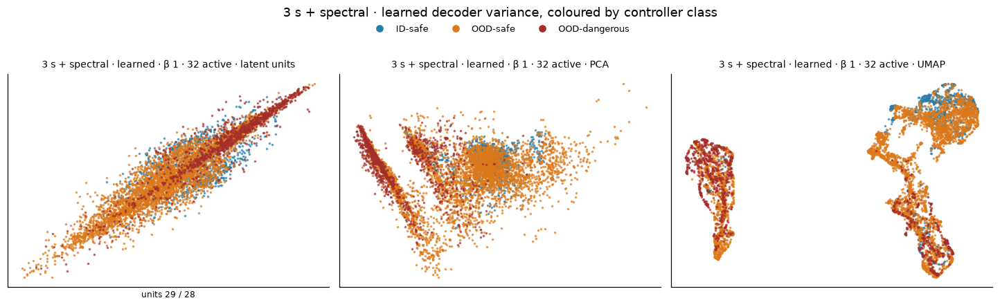

In [8]:
if HAVE_RUNS:
    base = shown.sort_values('inputs', ascending = False).iloc[0]                 # a 3 s run if any: its windows exist in every run
    first = runs[base.run]['labels']
    pick = lv.get_balanced_sample(first, 250, np.random.default_rng(0))
    labels = first.iloc[pick].reset_index(drop = True)
    views, actives = {}, {}
    for r in shown.itertuples():
        run = runs[r.run]
        z = lv.get_aligned_z({'labels': run['labels'], 'z': run['z']}, labels)                  # (N, 32), same windows
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        key = vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)
        views[key], actives[key] = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE), int(active.sum())
    keyed = {(' · '.join(k.split(' · ')[:2]), float(k.split(' · ')[2].removeprefix('β '))): v for k, v in views.items()}
    vr.plot_umap_by_beta(keyed, labels, 'family', lv.FAMILY_C, lv.BACKGROUND, 'UMAP of the posterior means by β, input and decoder variance '
                         f'(validation participants, seed {SHOWN_SEED}), coloured by task family', FIG_DIR / f'{NB}_{TAG}_umap_by_beta.png')
    print(f'{len(labels):,} validation windows, {labels.task.nunique()} tasks, participants {sorted(labels.subject.astype(str).unique())}')
    for group in dict.fromkeys(k[0] for k in keyed):
        part = {f'{k} · {actives[k]} active': v for k, v in views.items() if k.startswith(group + ' ·')}
        lv.plot_lens_grid(part, labels, 'family', lv.FAMILY_C, f'{group} decoder variance, coloured by task family')
        lv.plot_lens_grid(part, labels, 'controller_class', lv.CLASS_C, f'{group} decoder variance, coloured by controller class')


## 7. Interactive 3-D: the best fixed-variance and the best learned-variance VAE

The two cells drawn are chosen in notebook 05 (section 7.2's rule): for each decoder variance, the cell (β and input)
whose best native score has the highest validation AUROC for unfamiliar against familiar windows. Seed 0, the windows of
section 6 (up to 80 per task here), in 3-D; the dropdown switches view and lens. Besides task, family, controller class and
direction, a **KL quartile** lens colours each window by its KL in that run (light = lowest), because at high β the KL
is that model's novelty signal. Standalone copies are saved in `interactive/`.

In [9]:
import re

RESULTS = Path.cwd() / 'results' / '05_native_scores.csv'                    # written by notebook 05, section 7.2
INTERACTIVE = Path.cwd() / 'interactive'
CONFIG_3D = {'scrollZoom': True, 'displaylogo': False}
KL_C = {'1 lowest': '#c6dbef', '2': '#6baed6', '3': '#2171b5', '4 highest': '#08306b'}   # sequential: one hue, light to dark
if HAVE_RUNS and RESULTS.exists():
    native = pd.read_csv(RESULTS)
    native = native[native['family'] == 'vae']
    val_best = native.groupby(['model', 'score'])['val AUROC, unfamiliar vs familiar'].mean().groupby('model').max()
    found['model'] = [ns.get_model_label(r.config, r.stem) for r in found.itertuples()]
    STYLES = lv.get_task_styles(nt.TASK_FAMILIES)
    lenses = {'task': ('task', {t: STYLES[t]['family'] for ts in nt.TASK_FAMILIES.values() for t in ts}),
              'family': ('family', lv.FAMILY_C), 'controller class': ('controller_class', lv.CLASS_C),
              'direction': ('direction', lv.DIRECTION_C), 'KL quartile': ('kl_quartile', KL_C)}
    rng3 = np.random.default_rng(1)
    show = np.sort(np.concatenate([rng3.choice(np.flatnonzero(labels['task'].astype(str).to_numpy() == t),
                                               min(80, int((labels['task'] == t).sum())), replace = False)
                                    for t in labels['task'].astype(str).unique()]))
    for variance in ('fixed', 'learned'):
        candidates = val_best[[m for m in val_best.index if f'{variance} variance' in m and m.startswith(MODEL_PREFIX)]]
        if candidates.empty:
            print(f'no scored {variance}-variance runs of this architecture in {RESULTS.name} yet: run notebook 05 first')
            continue
        model = candidates.idxmax()
        r = found[(found['model'] == model) & (found['seed'] == SHOWN_SEED)].iloc[0]
        run = runs[r.run]
        idx = run['labels'][['rec', 'end']].reset_index().merge(labels[['rec', 'end']], on = ['rec', 'end'], how = 'right')['index'].to_numpy()
        lab3 = labels.copy()
        lab3['kl_quartile'] = pd.qcut(run['kl'][idx], 4, labels = list(KL_C)).astype(str)
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        z = run['z'][idx]
        v3 = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE)
        name = f'{model} (validation AUROC {candidates.max():.3f})'
        fig = lv.build_3d({name: {k: v[show] for k, v in v3.items() if k != 'units'}}, lab3.iloc[show].reset_index(drop = True),
                          lenses, {t: s['symbol'] for t, s in STYLES.items()}, name)
        INTERACTIVE.mkdir(exist_ok = True)
        path = INTERACTIVE / f'{TAG}_best_{variance}_3d.html'
        fig.write_html(path, include_plotlyjs = 'cdn', config = CONFIG_3D)
        fig.show(config = CONFIG_3D)
        print(f'best {variance}-variance cell: {model}; standalone copy {path.relative_to(REPO)}')
elif HAVE_RUNS:
    print('Run notebook 05 first: it writes results/05_native_scores.csv, which picks the cells shown here.')

best fixed-variance cell: VAE · β 1 · fixed variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/vae_best_fixed_3d.html


best learned-variance cell: VAE · β 1 · learned variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/vae_best_learned_3d.html


## 8. What this shows

The latent spaces only; how well any of these detects unfamiliar movement is notebook 05's question (section 9 there
compares the conv VAE with the five other model types on all four inputs).

**On 1 s raw windows (the full β grid)**

- **β prunes the code by whole filters.** With the variance fixed, β = 1 keeps all 32 dimensions (KL 60 per window),
  β = 8 keeps 19 ± 2, and from β = 32 on only 8 survive: one filter read across its 8 time steps (3.1). The Science
  Robotics sweep found the same 8-dimension floor at β = 16 and 32.
- **The learned decoder variance shifts that curve by about a factor of four in β.** It keeps all 32 dimensions at β = 8
  and 16 at β = 32, and reaches the 8-dimension floor only at β = 64. Its learned SDs explain why: the hip encoder
  angle is reconstructed to 0.09 of its SD and the sagittal thigh gyro to 0.18, against 0.7 to 0.8 for the out-of-plane
  gyro and accelerometer axes, so the likelihood weighs the sagittal signals up to a hundred times more and the code has
  more worth keeping. Its MSE is higher (0.277 against 0.246 at β = 1) because it spends less effort on channels it
  treats as noise.
- **At β = 1 with the variance fixed, the posterior means look like the plain AE's latent.** Gait rings for locomotion,
  a loop for jumping and running, the standing tasks in the middle (6), at the plain AE's reconstruction error (0.246
  against 0.247). As β grows the families mix; at the 8-dimension floor only jumping and running stay together.
- **Posterior width does not single out the unfamiliar tasks.** In every 1 s cell it is nearly flat across the 26 tasks
  (5); at high β the slow, posture-driven tasks (sit-to-stand, squats, lifting) are somewhat wider, but no more than some
  familiar ones are at other β. The Science Robotics study found the same with the fixed variance; the learned variance
  does not change it.
- **Training is consistent across seeds** in every cell (KL within ± 2 per window, active dimensions identical except
  at β = 8 with the fixed variance).

**Across the four inputs** (β 1, 32 and 128 with fixed variance and β 1 with the learned one on each; β 64 also on
3 s + spectral)

- **A longer window prunes less, because it weighs reconstruction more.** The NLL sums over the window's samples, so a
  3 s window triples the reconstruction term against the same KL: β 32 keeps 16 dimensions on 3 s raw against 8 on 1 s,
  and β 128 reaches the 8-dimension floor on both (3). The spectral features change nothing at 1 s (8 dimensions at β 32
  and 128) but keep 13 to 18 at β 32 to 128 on 3 s windows.
- **3 s raw keeps the task families apart at every β.** Its maps (6) keep separate rings for walking and stairs, a
  jumping-and-running cluster and the standing tasks apart even at β 128, where the 1 s latent has merged everything but
  jumping and running into one disc. With the spectral features the maps break into separate islands instead.
- **On 3 s windows the posterior width varies by task, but the wrong way for a novelty score.** At β 32 the vigorous
  unfamiliar tasks get the narrowest posteriors (jumping, running, cutting and dynamic walking: 0.12 to 0.25 on 3 s raw,
  0.06 to 0.10 with the spectral features), against 0.21 to 0.50 for the familiar tasks (5): the encoder is most certain
  about the largest movements. Consistent with this, the conv VAE's posterior variance reads downward on three of its
  four inputs in notebook 05, at 0.70 to 0.80.
- **The learned variance trusts the same channels on every input.** The hip encoder angle (0.09 to 0.28 of its SD) and
  the sagittal thigh gyro (0.18 to 0.29) are reconstructed most precisely, the thigh gyro's x axis and the
  accelerometer's y axis least (0.72 to 0.91), and the 3 s decoders are a little looser than the 1 s ones (4). Most
  spectral channels sit at 0.07 to 0.30; one per input is left loose (0.43 on 1 s, 0.56 on 3 s).
- **The 3-D pages** (7) show the cells chosen on validation in notebook 05, now both on 3 s raw: β 1 with fixed variance
  and β 1 with the learned one (before the ablation they were 1 s β 128 and 3 s + spectral β 1).

**Next**: notebook 05, section 9 scores these latents against the autoencoders, the LSTM-VAE (notebook 03) and the
Transformer VAE (notebook 04); the conv VAE on 3 s raw reaches 0.939 there, behind the LSTM-VAE (0.963).